# IC3 · CP1 · Stratul de observații
## S1 · Twin de mentenanță pentru motorul turbofan (NASA C-MAPSS)

**Autor:** Mutu Mihaela

**Întrebarea twin-ului:** câte cicluri mai poate zbura un motor până la defectare și cât de sigură este estimarea?
**Clientul:** echipa de mentenanță, care decide când oprește motorul pentru revizie.

Notebook-ul face tot stratul de observații, de la fișierele NASA până la data card:

1. găsește folderul cu date și calculează amprenta SHA-256 a fiecărui fișier (proveniența);
2. citește fișierele și dă nume celor 26 de coloane;
3. calculează ținta: ciclurile rămase până la defectare (RUL);
4. verifică integritatea datelor;
5. etichetează regimul de zbor și găsește senzorii care nu variază;
6. împarte motoarele de antrenare în antrenare și validare, pe motoare întregi;
7. calculează statisticile, desenează figura și scrie `datacard_S1.md`.

**Cum rulezi:** deschide notebook-ul în VS Code, alege un kernel Python 3.10+ și apasă *Run All*. Pachete necesare: `pip install pandas numpy matplotlib`. Datele nu se pun pe GitHub (`CMAPSSData/` este în `.gitignore`).

## 1. Configurare

`DATA_DIR` este folderul `CMAPSSData` descărcat de pe NASA. Dacă notebook-ul stă în același folder cu `CMAPSSData` (de exemplu în `Desktop/master/`), este găsit automat. Altfel, scrie calea completă în `DATA_DIR`.

`SOURCE` este textul care apare în data card la „sursă”. Schimbă-l dacă ai descărcat arhiva din alt loc.

In [5]:
import hashlib
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = '*/CMAPSSData'          # None = caută automat; altfel, de exemplu: Path.home() / "Desktop" / "master" / "CMAPSSData"
SEED = 42                # pentru împărțirea antrenare / validare
VAL_FRAC = 0.2           # 20% din motoarele de antrenare merg la validare
SAVE_PROCESSED = True    # salvează și datele procesate (CSV) în data_processed/

SUBSETS = ["FD001", "FD002", "FD003", "FD004"]
REQUIRED = [f"{kind}_{s}.txt" for s in SUBSETS for kind in ("train", "test", "RUL")]

REPORTS = Path("reports"); REPORTS.mkdir(exist_ok=True)
SPLITS = Path("splits"); SPLITS.mkdir(exist_ok=True)
PROCESSED = Path("data_processed")

def find_data_dir():
    # Locurile în care se uită, în ordine. Pe macOS, cu Desktop sincronizat în iCloud,
    # „iCloud Drive > Desktop” este tot ~/Desktop.
    candidates = [
        Path("CMAPSSData"),
        Path("..") / "CMAPSSData",
        Path.home() / "Desktop" / "master" / "CMAPSSData",
        Path.home() / "Library" / "Mobile Documents" / "com~apple~CloudDocs" / "Desktop" / "master" / "CMAPSSData",
    ]
    for c in candidates:
        if c.exists():
            hit = next(iter(sorted(c.rglob("train_FD001.txt"))), None)   # merge și dacă arhiva are un folder în plus
            if hit is not None:
                return hit.parent
    raise FileNotFoundError("Nu am găsit CMAPSSData. Scrie calea în DATA_DIR, în celula de mai sus.")

DATA_DIR = Path(DATA_DIR).expanduser() if DATA_DIR else find_data_dir()
missing = [f for f in REQUIRED if not (DATA_DIR / f).exists()]
assert not missing, f"Lipsesc fișierele: {missing}"
print("Date găsite în:", DATA_DIR.resolve())
print("Fișiere:", sorted(p.name for p in DATA_DIR.iterdir() if p.is_file()))

Date găsite în: /Users/mutumihaela/Desktop/master/IC3/CMAPSSData
Fișiere: ['Damage Propagation Modeling.pdf', 'RUL_FD001.txt', 'RUL_FD002.txt', 'RUL_FD003.txt', 'RUL_FD004.txt', 'readme.txt', 'test_FD001.txt', 'test_FD002.txt', 'test_FD003.txt', 'test_FD004.txt', 'train_FD001.txt', 'train_FD002.txt', 'train_FD003.txt', 'train_FD004.txt']


## 2. Proveniența datelor

Amprenta SHA-256 identifică exact fișierele folosite. Dacă cineva rulează notebook-ul pe alte fișiere, amprentele diferă. Rezultatul se salvează în `reports/provenance.json`.

In [6]:
def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

files = REQUIRED + (["readme.txt"] if (DATA_DIR / "readme.txt").exists() else [])
provenance = {
    "source": SOURCE,
    "computed_utc": pd.Timestamp.now(tz="UTC").strftime("%Y-%m-%dT%H:%M:%SZ"),
    "files": {f: {"bytes": (DATA_DIR / f).stat().st_size, "sha256": sha256(DATA_DIR / f)} for f in sorted(files)},
}
(REPORTS / "provenance.json").write_text(json.dumps(provenance, indent=2))
pd.DataFrame(provenance["files"]).T

,bytes,sha256
RUL_FD001.txt,429,a19c8ec94931949d0485bdc35118206e9c81c4547b422e...
RUL_FD002.txt,1110,c851dd96a6ea6998d3c4a8f834d3c8013aa90e93a6ed95...
RUL_FD003.txt,428,df1e0566306b174a2de41c67a3e7a51877889598b78643...
RUL_FD004.txt,1084,196b836b85a95ac7fdbbf29c5fdf1657382eafa445644d...
readme.txt,2442,4f5270554b775c67e73aff383c5436fd329d6e4cc3d3a1...
test_FD001.txt,2228855,3cda7109ce17bafb5443f2ac926cfcf88154b941b8c4cf...
test_FD002.txt,5734587,de7b5bf7e998a985c378488480528b7c02cff1406a4674...
test_FD003.txt,2826651,299babd63c8d987cef079c4a425429f33b3a34797d803b...
test_FD004.txt,6957759,1dc675fff0624bac10786927c6715b37d1297657137400...
train_FD001.txt,3515356,963b5e22825b34d8b21c69e1aeb4af3e647050eb672ee8...


## 3. Coloanele și senzorii

Fișierele nu au antet. Ordinea coloanelor vine din `readme.txt`: motor, ciclu, 3 setări de operare, 21 de senzori. Simbolurile, descrierile și unitățile senzorilor sunt din Tabelul 2 din Saxena, Goebel, Simon, Eklund (2008), *Damage Propagation Modeling for Aircraft Engine Run-to-Failure Simulation* (PDF-ul este în folderul cu date).

Grupa fiecărui senzor (temperatură, presiune, turație, debit / raport) va fi folosită la ablația pe surse de la CP4.

In [7]:
SENSORS = [
    ("T2", "Total temperature at fan inlet", "°R", "temperatură"),
    ("T24", "Total temperature at LPC outlet", "°R", "temperatură"),
    ("T30", "Total temperature at HPC outlet", "°R", "temperatură"),
    ("T50", "Total temperature at LPT outlet", "°R", "temperatură"),
    ("P2", "Pressure at fan inlet", "psia", "presiune"),
    ("P15", "Total pressure in bypass-duct", "psia", "presiune"),
    ("P30", "Total pressure at HPC outlet", "psia", "presiune"),
    ("Nf", "Physical fan speed", "rpm", "turație"),
    ("Nc", "Physical core speed", "rpm", "turație"),
    ("epr", "Engine pressure ratio (P50/P2)", "-", "presiune"),
    ("Ps30", "Static pressure at HPC outlet", "psia", "presiune"),
    ("phi", "Ratio of fuel flow to Ps30", "pps/psi", "debit / raport"),
    ("NRf", "Corrected fan speed", "rpm", "turație"),
    ("NRc", "Corrected core speed", "rpm", "turație"),
    ("BPR", "Bypass ratio", "-", "debit / raport"),
    ("farB", "Burner fuel-air ratio", "-", "debit / raport"),
    ("htBleed", "Bleed enthalpy", "-", "debit / raport"),
    ("Nf_dmd", "Demanded fan speed", "rpm", "turație"),
    ("PCNfR_dmd", "Demanded corrected fan speed", "rpm", "turație"),
    ("W31", "HPT coolant bleed", "lbm/s", "debit / raport"),
    ("W32", "LPT coolant bleed", "lbm/s", "debit / raport"),
]
SENSOR_COLS = [f"s{i}" for i in range(1, 22)]
SETTING_COLS = ["setting_1", "setting_2", "setting_3"]
RAW_COLS = ["unit", "cycle"] + SETTING_COLS + SENSOR_COLS          # 26 de coloane
SENSOR_INFO = pd.DataFrame(SENSORS, index=SENSOR_COLS, columns=["simbol", "descriere", "unitate", "grupă"])

# Numărul de motoare din fișiere și ce spune readme.txt despre regimuri și defecte.
EXPECTED = {
    "FD001": {"train_units": 100, "test_units": 100, "conditions": 1, "fault_modes": "HPC"},
    "FD002": {"train_units": 260, "test_units": 259, "conditions": 6, "fault_modes": "HPC"},
    "FD003": {"train_units": 100, "test_units": 100, "conditions": 1, "fault_modes": "HPC + ventilator"},
    "FD004": {"train_units": 249, "test_units": 248, "conditions": 6, "fault_modes": "HPC + ventilator"},
}
SENSOR_INFO

,simbol,descriere,unitate,grupă
s1,T2,Total temperature at fan inlet,°R,temperatură
s2,T24,Total temperature at LPC outlet,°R,temperatură
s3,T30,Total temperature at HPC outlet,°R,temperatură
s4,T50,Total temperature at LPT outlet,°R,temperatură
s5,P2,Pressure at fan inlet,psia,presiune
s6,P15,Total pressure in bypass-duct,psia,presiune
s7,P30,Total pressure at HPC outlet,psia,presiune
s8,Nf,Physical fan speed,rpm,turație
s9,Nc,Physical core speed,rpm,turație
s10,epr,Engine pressure ratio (P50/P2),-,presiune


## 4. Citirea datelor și ținta (RUL)

- **Antrenare:** motorul merge până la defectare, deci RUL = ultimul ciclu − ciclul curent (0 la defectare).
- **Test:** seria se oprește înainte de defectare. `RUL_FD00x.txt` dă RUL-ul real la ultimul ciclu observat al fiecărui motor; pentru ciclurile anterioare RUL = valoarea din fișier + ciclurile rămase până la sfârșitul seriei. Evaluarea standard folosește doar ultimul ciclu al fiecărui motor de test.

In [8]:
def read_raw(path):
    # Coloanele sunt separate prin spații, iar unele rânduri se termină cu spații în plus.
    df = pd.read_csv(path, sep=r"\s+", header=None)
    assert df.shape[1] == len(RAW_COLS), f"{path}: {df.shape[1]} coloane în loc de 26"
    df.columns = RAW_COLS
    df[["unit", "cycle"]] = df[["unit", "cycle"]].astype(int)
    return df

def load_subset(s):
    train = read_raw(DATA_DIR / f"train_{s}.txt")
    test = read_raw(DATA_DIR / f"test_{s}.txt")
    rul_last = pd.read_csv(DATA_DIR / f"RUL_{s}.txt", sep=r"\s+", header=None)[0].astype(int)

    train["rul"] = train.groupby("unit")["cycle"].transform("max") - train["cycle"]

    test_units = np.sort(test["unit"].unique())
    assert len(rul_last) == len(test_units), f"{s}: RUL_{s}.txt are {len(rul_last)} rânduri pentru {len(test_units)} motoare"
    rul_map = dict(zip(test_units, rul_last.values))
    last = test.groupby("unit")["cycle"].transform("max")
    test["rul"] = test["unit"].map(rul_map) + (last - test["cycle"])
    return train, test, len(rul_last)

DATA = {}
for s in SUBSETS:
    train, test, n_rul = load_subset(s)
    DATA[s] = {"train": train, "test": test, "rul_rows": n_rul}
    print(f"{s}: antrenare {train.shape}, test {test.shape}, rânduri în RUL_{s}.txt: {n_rul}")

DATA["FD001"]["train"].head()

FD001: antrenare (20631, 27), test (13096, 27), rânduri în RUL_FD001.txt: 100
FD002: antrenare (53759, 27), test (33991, 27), rânduri în RUL_FD002.txt: 259
FD003: antrenare (24720, 27), test (16596, 27), rânduri în RUL_FD003.txt: 100
FD004: antrenare (61249, 27), test (41214, 27), rânduri în RUL_FD004.txt: 248


,unit,cycle,setting_1,setting_2,setting_3,s1,s2,s3,s4,s5,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,rul
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187


## 5. Verificări de integritate

Fiecare verificare primește un nume și un rezultat. Dacă una pică, notebook-ul se oprește la finalul celulei, cu numele verificării.

In [9]:
CHECKS = []

def check(name, ok):
    CHECKS.append({"verificare": name, "rezultat": "OK" if ok else "EȘUAT"})

for s in SUBSETS:
    tr, te = DATA[s]["train"], DATA[s]["test"]
    exp = EXPECTED[s]
    check(f"{s}: {exp['train_units']} motoare de antrenare", tr["unit"].nunique() == exp["train_units"])
    check(f"{s}: {exp['test_units']} motoare de test", te["unit"].nunique() == exp["test_units"])
    check(f"{s}: RUL_{s}.txt are câte un rând pentru fiecare motor de test", DATA[s]["rul_rows"] == te["unit"].nunique())
    for name, df in (("antrenare", tr), ("test", te)):
        g = df.groupby("unit")["cycle"]
        check(f"{s} {name}: nicio valoare lipsă", not df[RAW_COLS].isna().any().any())
        check(f"{s} {name}: fiecare motor începe la ciclul 1", bool((g.min() == 1).all()))
        check(f"{s} {name}: ciclurile sunt consecutive, fără goluri sau duplicate", bool((g.count() == g.max()).all()))
        check(f"{s} {name}: RUL scade cu exact 1 pe ciclu", bool((df.groupby("unit")["rul"].diff().dropna() == -1).all()))
    check(f"{s} antrenare: RUL ajunge la 0 la fiecare motor", bool((tr.groupby("unit")["rul"].min() == 0).all()))
    check(f"{s} test: RUL este pozitiv", bool((te["rul"] > 0).all()))

checks = pd.DataFrame(CHECKS)
print(f"{(checks.rezultat == 'OK').sum()} din {len(checks)} verificări trec")
failed = checks[checks.rezultat != "OK"]
assert failed.empty, f"Verificări eșuate:\n{failed}"
checks

52 din 52 verificări trec


,verificare,rezultat
0,FD001: 100 motoare de antrenare,OK
1,FD001: 100 motoare de test,OK
2,FD001: RUL_FD001.txt are câte un rând pentru f...,OK
3,FD001 antrenare: nicio valoare lipsă,OK
4,FD001 antrenare: fiecare motor începe la ciclul 1,OK
5,"FD001 antrenare: ciclurile sunt consecutive, f...",OK
6,FD001 antrenare: RUL scade cu exact 1 pe ciclu,OK
7,FD001 test: nicio valoare lipsă,OK
8,FD001 test: fiecare motor începe la ciclul 1,OK
9,"FD001 test: ciclurile sunt consecutive, fără g...",OK


### Ce spune `readme.txt` față de fișiere

Comparăm numărul de motoare scris în `readme.txt` cu cel găsit în fișiere.

In [10]:
readme_counts = {}
readme_path = DATA_DIR / "readme.txt"
if readme_path.exists():
    txt = readme_path.read_text(errors="replace")
    for s, block in re.findall(r"Data Set:\s*(FD00\d)(.*?)(?=Data Set:|$)", txt, flags=re.S):
        tr_n = re.search(r"Train\s+tr\w*:\s*(\d+)", block)
        te_n = re.search(r"Test\s+tr\w*:\s*(\d+)", block)
        if tr_n and te_n:
            readme_counts[s] = (int(tr_n.group(1)), int(te_n.group(1)))

readme_cmp = pd.DataFrame([
    {"subset": s,
     "readme antrenare / test": "{} / {}".format(*readme_counts[s]) if s in readme_counts else "–",
     "fișiere antrenare / test": f"{DATA[s]['train']['unit'].nunique()} / {DATA[s]['test']['unit'].nunique()}"}
    for s in SUBSETS])
readme_cmp["la fel"] = readme_cmp["readme antrenare / test"] == readme_cmp["fișiere antrenare / test"]
readme_cmp

,subset,readme antrenare / test,fișiere antrenare / test,la fel
0,FD001,100 / 100,100 / 100,True
1,FD002,260 / 259,260 / 259,True
2,FD003,100 / 100,100 / 100,True
3,FD004,248 / 249,249 / 248,False


## 6. Regimul de zbor și senzorii care nu variază

Cele 3 setări de operare (altitudine, număr Mach, unghiul manetei de accelerație) au zgomot în jurul unor valori fixe. Rotunjirea lor e suficientă ca să recuperăm regimul de zbor: 1 regim la FD001 și FD003, 6 la FD002 și FD004.

Un senzor **constant** are o singură valoare; unul **aproape constant** are doar 2 valori (pași de rotunjire). Niciunul nu spune nimic despre degradare, deci nu intră în model. La FD002 și FD004 fiecare senzor se schimbă odată cu regimul de zbor, așa că verificăm constanța în fiecare regim separat.

In [11]:
def operating_regime(df):
    # „+ 0.0” transformă -0.0 în 0.0, ca zgomotul negativ mic să nu creeze un regim fals
    key = ((df["setting_1"].round(0) + 0.0).astype(str) + "_"
           + (df["setting_2"].round(2) + 0.0).astype(str) + "_"
           + (df["setting_3"].round(0) + 0.0).astype(str))
    return pd.Series(pd.factorize(key, sort=True)[0], index=df.index)

def constant_columns(df, by=None):
    n = df[SENSOR_COLS].nunique() if by is None else df.groupby(by)[SENSOR_COLS].nunique().max()
    return [c for c in SENSOR_COLS if n[c] == 1], [c for c in SENSOR_COLS if n[c] == 2]

rows = []
for s in SUBSETS:
    tr, te = DATA[s]["train"], DATA[s]["test"]
    tr["regime"], te["regime"] = operating_regime(tr), operating_regime(te)
    multi = EXPECTED[s]["conditions"] > 1
    const, quasi = constant_columns(tr, by="regime" if multi else None)
    DATA[s].update(const=const, quasi=quasi, keep=[c for c in SENSOR_COLS if c not in const + quasi],
                   const_rule="în fiecare regim de zbor" if multi else "pe tot setul de antrenare")
    check(f"{s}: {EXPECTED[s]['conditions']} regim(uri) de zbor", tr["regime"].nunique() == EXPECTED[s]["conditions"])
    rows.append({"subset": s, "regimuri": tr["regime"].nunique(), "constanți": const,
                 "aproape constanți": quasi, "senzori păstrați": len(DATA[s]["keep"])})
assert all(c["rezultat"] == "OK" for c in CHECKS)
pd.DataFrame(rows)

,subset,regimuri,constanți,aproape constanți,senzori păstrați
0,FD001,1,"[s1, s5, s10, s16, s18, s19]",[s6],14
1,FD002,6,"[s1, s5, s18, s19]","[s10, s16]",15
2,FD003,1,"[s1, s5, s16, s18, s19]",[],16
3,FD004,6,"[s1, s5, s18, s19]",[s16],16


## 7. Împărțirea pe motoare: antrenare / validare / test

- **Test:** fișierele `test_FD00x` de la NASA rămân neatinse până la evaluarea finală.
- **Validare:** 20% din motoarele de antrenare, alese aleator cu seed fix. Un motor este fie în antrenare, fie în validare. O împărțire pe rânduri ar pune cicluri vecine ale aceluiași motor în ambele părți și ar umfla rezultatele.
- Listele de motoare se salvează în `splits/`, ca împărțirea să fie aceeași în toate experimentele următoare.

In [12]:
def split_engines(units, val_frac=VAL_FRAC, seed=SEED):
    units = np.sort(np.asarray(units))
    rng = np.random.default_rng(seed)
    val = np.sort(rng.choice(units, size=int(round(len(units) * val_frac)), replace=False))
    return np.setdiff1d(units, val).tolist(), val.tolist()

rows = []
for s in SUBSETS:
    tr = DATA[s]["train"]
    tr_units, va_units = split_engines(tr["unit"].unique())
    check(f"{s}: niciun motor nu e și în antrenare, și în validare", not set(tr_units) & set(va_units))
    check(f"{s}: toate motoarele sunt împărțite", sorted(tr_units + va_units) == sorted(tr["unit"].unique().tolist()))
    tr["split"] = np.where(tr["unit"].isin(va_units), "val", "train")
    (SPLITS / f"{s}_split.json").write_text(json.dumps(
        {"subset": s, "seed": SEED, "val_frac": VAL_FRAC, "rule": "split by engine id; NASA test set untouched",
         "train_units": tr_units, "val_units": va_units}, indent=1))
    DATA[s]["split"] = {"train_engines": len(tr_units), "val_engines": len(va_units),
                        "train_rows": int((tr["split"] == "train").sum()), "val_rows": int((tr["split"] == "val").sum())}
    rows.append({"subset": s, **DATA[s]["split"], "test_engines": DATA[s]["test"]["unit"].nunique(),
                 "test_rows": len(DATA[s]["test"])})
assert all(c["rezultat"] == "OK" for c in CHECKS)
pd.DataFrame(rows)

,subset,train_engines,val_engines,train_rows,val_rows,test_engines,test_rows
0,FD001,80,20,16390,4241,100,13096
1,FD002,208,52,43206,10553,259,33991
2,FD003,80,20,19827,4893,100,16596
3,FD004,199,50,49147,12102,248,41214


## 8. Statisticile pentru data card

Toate cifrele din data card vin din această celulă și se salvează în `reports/datacard_stats.json`.

In [13]:
def desc(x):
    return {"min": int(x.min()), "median": float(x.median()), "max": int(x.max())}

stats = {"author": AUTHOR, "source": SOURCE, "seed": SEED, "val_frac": VAL_FRAC, "subsets": {}}
for s in SUBSETS:
    tr, te = DATA[s]["train"], DATA[s]["test"]
    stats["subsets"][s] = {
        "train_units": int(tr["unit"].nunique()), "test_units": int(te["unit"].nunique()),
        "train_rows": len(tr), "test_rows": len(te),
        "missing_values": int(tr[RAW_COLS].isna().sum().sum() + te[RAW_COLS].isna().sum().sum()),
        "flight_conditions": int(tr["regime"].nunique()), "fault_modes": EXPECTED[s]["fault_modes"],
        "train_lifetime_cycles": desc(tr.groupby("unit")["cycle"].max()),
        "test_observed_cycles": desc(te.groupby("unit")["cycle"].max()),
        "test_true_rul_last_cycle": desc(te.groupby("unit")["rul"].min()),
        "settings_range": {c: [round(float(tr[c].min()), 4), round(float(tr[c].max()), 4)] for c in SETTING_COLS},
        "constant_sensors": DATA[s]["const"], "quasi_constant_sensors": DATA[s]["quasi"],
        "constant_rule": DATA[s]["const_rule"], "sensors_kept": DATA[s]["keep"], "split": DATA[s]["split"],
        "sensor_range_train": {c: [float(tr[c].min()), float(tr[c].max())] for c in SENSOR_COLS},
        "readme_train_test": list(readme_counts.get(s, [])),
    }
stats["checks_passed"] = int(sum(c["rezultat"] == "OK" for c in CHECKS))
stats["checks_total"] = len(CHECKS)
(REPORTS / "datacard_stats.json").write_text(json.dumps(stats, indent=1, ensure_ascii=False))

summary = pd.DataFrame({s: {
    "motoare antrenare": d["train_units"], "rânduri antrenare": d["train_rows"],
    "motoare test": d["test_units"], "rânduri test": d["test_rows"],
    "regimuri de zbor": d["flight_conditions"], "moduri de defect": d["fault_modes"],
    "durata de viață min / mediană / max": "{min} / {median:g} / {max}".format(**d["train_lifetime_cycles"]),
    "cicluri observate în test": "{min}–{max}".format(**d["test_observed_cycles"]),
    "RUL real la ultimul ciclu": "{min}–{max}".format(**d["test_true_rul_last_cycle"]),
} for s, d in stats["subsets"].items()}).T
print(f"Verificări: {stats['checks_passed']} din {stats['checks_total']} trec")
summary

Verificări: 64 din 64 trec


,motoare antrenare,rânduri antrenare,motoare test,rânduri test,regimuri de zbor,moduri de defect,durata de viață min / mediană / max,cicluri observate în test,RUL real la ultimul ciclu
FD001,100,20631,100,13096,1,HPC,128 / 199 / 362,31–303,7–145
FD002,260,53759,259,33991,6,HPC,128 / 199 / 378,21–367,6–194
FD003,100,24720,100,16596,1,HPC + ventilator,145 / 220.5 / 525,38–475,6–145
FD004,249,61249,248,41214,6,HPC + ventilator,128 / 234 / 543,19–486,6–195


## 9. Figura din data card

A: cât trăiesc motoarele de antrenare în fiecare subset. B: temperatura T50 (senzorul s4) crește pe măsură ce motorul se apropie de defectare; pe asta se bazează estimarea RUL.

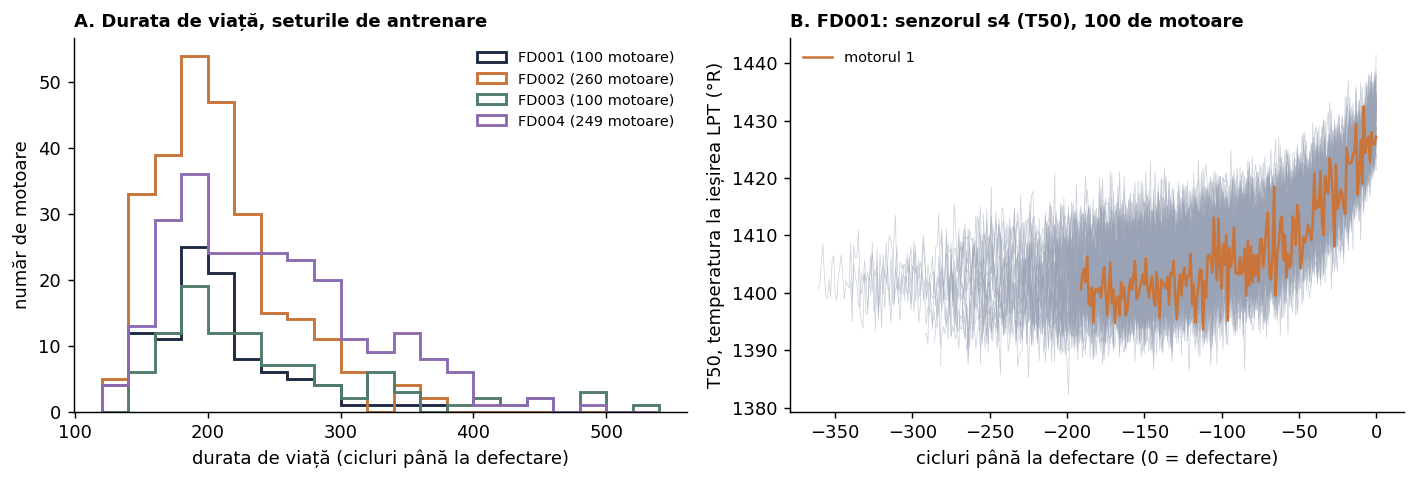

In [14]:
COLORS = {"FD001": "#1E2A44", "FD002": "#C8743A", "FD003": "#4F7C6B", "FD004": "#8C6BB1"}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), dpi=130)

ax = axes[0]
for s in SUBSETS:
    life = DATA[s]["train"].groupby("unit")["cycle"].max()
    ax.hist(life, bins=range(120, 560, 20), histtype="step", lw=1.6, color=COLORS[s], label=f"{s} ({len(life)} motoare)")
ax.set_xlabel("durata de viață (cicluri până la defectare)")
ax.set_ylabel("număr de motoare")
ax.set_title("A. Durata de viață, seturile de antrenare", loc="left", fontsize=10, weight="bold")
ax.legend(frameon=False, fontsize=8)

ax = axes[1]
tr = DATA["FD001"]["train"]
for u, g in tr.groupby("unit"):
    ax.plot(-g["rul"], g["s4"], color="#9AA3B5", lw=0.4, alpha=0.5)
g = tr[tr["unit"] == 1]
ax.plot(-g["rul"], g["s4"], color="#C8743A", lw=1.4, label="motorul 1")
ax.set_xlabel("cicluri până la defectare (0 = defectare)")
ax.set_ylabel("T50, temperatura la ieșirea LPT (°R)")
ax.set_title("B. FD001: senzorul s4 (T50), 100 de motoare", loc="left", fontsize=10, weight="bold")
ax.legend(frameon=False, fontsize=8, loc="upper left")
for a in axes:
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(REPORTS / "fig_datacard.png", bbox_inches="tight")
plt.show()

## 10. Salvarea datelor procesate

Datele procesate (cu RUL, regim de zbor și coloana `split`) se salvează în `data_processed/`, pentru CP2. Folderul nu se pune pe GitHub.

In [15]:
if SAVE_PROCESSED:
    PROCESSED.mkdir(exist_ok=True)
    for s in SUBSETS:
        DATA[s]["train"].to_csv(PROCESSED / f"{s}_train.csv", index=False)
        DATA[s]["test"].to_csv(PROCESSED / f"{s}_test.csv", index=False)
    print("Salvat în", PROCESSED.resolve())

Salvat în /Users/mutumihaela/Downloads/ic3-s1-cmapss/data_processed


## 11. Data card-ul

Celula scrie `datacard_S1.md` numai din `stats`, deci cifrele din data card sunt mereu cele din rularea curentă.

In [16]:
def ro(x):              # 20631 -> "20 631"
    return f"{x:,.0f}".replace(",", " ")

def rog(x):             # 518.67 -> "518,67"
    return f"{x:g}".replace(".", ",")

def nr(n, word):        # 19 cicluri, 20 de cicluri, 248 de motoare
    return f"{n} {word}" if 1 <= n % 100 <= 19 else f"{n} de {word}"

def cicluri(n):
    return nr(n, "cicluri")

def sym(cols):
    return ", ".join(f"{c} ({SENSOR_INFO.loc[c, 'simbol']})" for c in cols) or "niciunul"

S, sub = stats, stats["subsets"]
tot = {k: sum(sub[s][k] for s in SUBSETS) for k in ("train_units", "test_units", "train_rows", "test_rows")}
f1, f2 = sub["FD001"], sub["FD002"]

size_rows = "\n".join(
    f"| {s} | {d['train_units']} | {ro(d['train_rows'])} | {d['test_units']} | {ro(d['test_rows'])} "
    f"| {d['flight_conditions']} | {d['fault_modes']} "
    f"| {d['train_lifetime_cycles']['min']} / {rog(d['train_lifetime_cycles']['median'])} / {d['train_lifetime_cycles']['max']} "
    f"| {d['test_observed_cycles']['min']}–{d['test_observed_cycles']['max']} "
    f"| {d['test_true_rul_last_cycle']['min']}–{d['test_true_rul_last_cycle']['max']} |" for s, d in sub.items())
var_rows = "\n".join(
    f"| {c} | {r.simbol} | {r.descriere} | {r.unitate} | {r['grupă']} "
    f"| {rog(f1['sensor_range_train'][c][0])} – {rog(f1['sensor_range_train'][c][1])} |" for c, r in SENSOR_INFO.iterrows())
const_rows = "\n".join(
    f"| {s} | {d['constant_rule']} | {sym(d['constant_sensors'])} | {sym(d['quasi_constant_sensors'])} | {len(d['sensors_kept'])} |"
    for s, d in sub.items())
split_rows = "\n".join(
    f"| {s} | {d['split']['train_engines']} motoare / {ro(d['split']['train_rows'])} rânduri "
    f"| {d['split']['val_engines']} motoare / {ro(d['split']['val_rows'])} rânduri "
    f"| {d['test_units']} motoare / {ro(d['test_rows'])} rânduri |" for s, d in sub.items())

diff = [s for s in SUBSETS if sub[s]["readme_train_test"] and
        tuple(sub[s]["readme_train_test"]) != (sub[s]["train_units"], sub[s]["test_units"])]
if not readme_counts:
    readme_note = "`readme.txt` nu a fost găsit, deci numerele nu au fost comparate cu el."
elif diff:
    readme_note = " ".join(
        f"Observație: `readme.txt` spune că {s} are {nr(sub[s]['readme_train_test'][0], 'motoare')} de antrenare și "
        f"{nr(sub[s]['readme_train_test'][1], 'motoare')} de test. Fișierele au {nr(sub[s]['train_units'], 'motoare')} de antrenare și "
        f"{nr(sub[s]['test_units'], 'motoare')} de test, iar `RUL_{s}.txt` are {nr(DATA[s]['rul_rows'], 'rânduri')}."
        + (" Readme-ul inversează cele două numere." if tuple(sub[s]['readme_train_test']) == (sub[s]['test_units'], sub[s]['train_units']) else "")
        for s in diff) + " Notebook-ul verifică numerele din fișiere."
else:
    readme_note = "Numărul de motoare din fișiere coincide cu cel din `readme.txt`."

dropped_f1 = ", ".join(sorted(f1["constant_sensors"] + f1["quasi_constant_sensors"], key=lambda c: int(c[1:])))
n_tr_u, n_te_u = tot["train_units"], tot["test_units"]
n_tr_r, n_te_r = ro(tot["train_rows"]), ro(tot["test_rows"])
n_missing = sum(d["missing_values"] for d in sub.values())
val_pct, seed, val_frac = round(S["val_frac"] * 100), S["seed"], rog(S["val_frac"])
source, n_checks = S["source"], S["checks_total"]
life_min = min(d["train_lifetime_cycles"]["min"] for d in sub.values())
life_max = cicluri(max(d["train_lifetime_cycles"]["max"] for d in sub.values()))
test_min = cicluri(min(d["test_observed_cycles"]["min"] for d in sub.values()))
r1, r2, r3 = (f2["settings_range"][c] for c in SETTING_COLS)

text = f'''# Data card: NASA C-MAPSS (tema S1, IC3)

Mini-twin: mentenanța unui motor turbofan · Autor: {AUTHOR} · CP1, stratul de observații

Cifrele din acest document sunt scrise de notebook-ul `CP1_S1.ipynb` (secțiunea 11), din rularea curentă. Nu sunt copiate manual.

## 1. Pe scurt

| Câmp | Valoare |
|---|---|
| Ce conține | Serii de timp multivariate pentru o flotă simulată de motoare turbofan, de la funcționare normală până la defectare (antrenare) sau până la un moment înainte de defectare (test). |
| Sursă | NASA Ames, Prognostics Center of Excellence (PCoE). Date generate cu simulatorul C-MAPSS. Referință: Saxena, Goebel, Simon, Eklund (2008). |
| Unde se descarcă | `CMAPSSData.zip` de pe https://data.nasa.gov/dataset/cmapss-jet-engine-simulated-data (fișier: https://data.nasa.gov/docs/legacy/CMAPSSData.zip) sau din NASA PCoE Data Set Repository. |
| Perioadă | Fără timp calendaristic. Axa de timp este ciclul de zbor. Setul a fost publicat în 2008 pentru competiția PHM08. Pe data.nasa.gov: ultima modificare 15 mai 2024. |
| Rezoluție | Temporală: un rând pe motor pe ciclu de zbor (un instantaneu pe zbor). Spațială: nu se aplică; obiectul este motorul. |
| Unități | Temperaturi în °R, presiuni în psia, turații în rpm, debite în lbm/s, phi în pps/psi, restul fără unitate (secțiunea 4). Fișierele nu conțin nume de coloane sau unități. |
| Dimensiune | {n_tr_u} motoare de antrenare ({n_tr_r} rânduri) și {n_te_u} motoare de test ({n_te_r} rânduri), în 4 subseturi. 26 de coloane: motor, ciclu, 3 setări de operare, 21 de senzori. |
| Goluri | {n_missing} valori lipsă. Ciclurile sunt consecutive, fără salturi sau duplicate. Unii senzori sunt constanți (secțiunea 6). Seriile de test sunt trunchiate intenționat. |
| Împărțire train/test | Test: fișierele `test_FD00x` de la NASA, cu RUL-ul real în `RUL_FD00x`, folosite doar la evaluarea finală. Validare: {val_pct}% din motoarele de antrenare, alese cu seed {seed}, motoare întregi (secțiunea 7). |
| Licență | Nespecificată. data.nasa.gov afișează „License not specified”. Depozitul PCoE cere citarea depozitului și a autorilor datelor și precizează că datele se folosesc pe propriul risc. |

## 2. Sursă și proveniență

- Producător: NASA Ames Research Center, Prognostics Center of Excellence. Întreținător pe data.nasa.gov: Chris Teubert.
- Cum au fost generate: simulatorul C-MAPSS al unui motor turbofan comercial mare. Fiecare motor pornește cu uzură inițială și variații de fabricație diferite, necunoscute. Un defect apare la un moment dat și crește până la defectare. Peste ieșiri s-a adăugat zgomot de măsurare (Saxena et al., 2008).
- Fișiere folosite: `train_FD001…FD004.txt`, `test_FD001…FD004.txt`, `RUL_FD001…FD004.txt`, `readme.txt`.
- Proveniență: {source}. Amprenta SHA-256 a fiecărui fișier este în `reports/provenance.json`.

## 3. Dimensiuni pe subset

Durata de viață = numărul de cicluri până la defectare al unui motor de antrenare. Pentru test, „cicluri observate” = cât din serie este dat, iar „RUL real” = câte cicluri mai avea motorul după ultimul ciclu observat.

| Subset | Motoare antrenare | Rânduri antrenare | Motoare test | Rânduri test | Regimuri de zbor | Moduri de defect | Durata de viață min / mediană / max | Cicluri observate în test | RUL real la ultimul ciclu |
|---|---|---|---|---|---|---|---|---|---|
{size_rows}

{readme_note}

## 4. Variabile și unități

Coloanele 1–2: `unit` (numărul motorului) și `cycle` (ciclul de zbor, începe de la 1).

Coloanele 3–5: setările de operare. Saxena et al. (2008) definesc regimul de zbor prin altitudine (0–42 000 ft), număr Mach (0–0,84) și unghiul manetei de accelerație (TRA, până la 100). Fișierele nu spun care coloană e care. Intervalele din FD002 se potrivesc: `setting_1` între {rog(r1[0])} și {rog(r1[1])} (altitudine, în mii de ft), `setting_2` între {rog(r2[0])} și {rog(r2[1])} (Mach), `setting_3` între {rog(r3[0])} și {rog(r3[1])} (TRA). Atribuirea este o deducție din intervale. În FD001 și FD003 setările variază doar cu zgomot în jurul unui singur regim.

Coloanele 6–26: cei 21 de senzori. Simbolurile, descrierile și unitățile sunt din Tabelul 2 din Saxena et al. (2008). Grupa e folosită mai târziu pentru ablația pe surse. Intervalul este cel observat în setul de antrenare FD001.

| Coloană | Simbol | Descriere (Saxena et al., 2008) | Unitate | Grupă | Interval FD001 |
|---|---|---|---|---|---|
{var_rows}

## 5. Ținta: ciclurile rămase (RUL)

- Antrenare: motorul merge până la defectare, deci RUL = ultimul ciclu − ciclul curent. RUL este 0 la ciclul defectării.
- Test: seria se oprește înainte de defectare. `RUL_FD00x.txt` dă RUL-ul real la ultimul ciclu observat al fiecărui motor. Notebook-ul calculează RUL și pentru ciclurile anterioare, dar evaluarea standard folosește doar ultimul ciclu.
- Plafonarea RUL-ului (de exemplu la 125 de cicluri, presupunând că degradarea nu se vede la început) nu e aplicată în datele salvate. Este o decizie de reprezentare pentru CP2. În literatură se folosesc valori între 115 și 135 (Ellefsen et al., 2019).

## 6. Goluri, calitate și senzori fără informație

- Valori lipsă: {n_missing} în toate cele 8 fișiere de date.
- Continuitate: la fiecare motor ciclurile încep de la 1 și cresc din 1 în 1. Toate cele {n_checks} de verificări din notebook (secțiunile 5–7) trec.
- Lungimi inegale: motoarele de antrenare trăiesc între {life_min} și {life_max}. Un model pe ferestre trebuie să trateze și seriile de test scurte: cea mai scurtă are {test_min}. Figura `reports/fig_datacard.png` arată distribuția duratelor de viață și evoluția senzorului T50.
- Zgomot: adăugat intenționat de NASA la toate ieșirile.
- Senzori constanți: nu poartă informație despre degradare și se elimină. La FD002 și FD004 fiecare senzor se mișcă odată cu regimul de zbor, deci constanța se verifică în fiecare regim.

| Subset | Unde se verifică constanța | Constanți (o singură valoare) | Aproape constanți (2 valori) | Senzori păstrați |
|---|---|---|---|---|
{const_rows}

La FD001 lista eliminată ({dropped_f1}) coincide cu cea folosită de Ellefsen et al. (2019). Datele salvate păstrează toate coloanele; lista `sensors_kept` din `reports/datacard_stats.json` spune ce intră în model.

## 7. Împărțirea datelor și reguli contra scurgerii de informație

| Subset | Antrenare | Validare | Test (NASA) |
|---|---|---|---|
{split_rows}

- Validarea se face pe motoare întregi: un motor este fie în antrenare, fie în validare. O împărțire aleatoare pe rânduri ar pune cicluri vecine ale aceluiași motor în ambele părți și ar umfla rezultatele.
- Echivalentul LOYO din planul cursului este aici „motoare nevăzute”: twin-ul trebuie să funcționeze pe un motor nou.
- Normalizarea senzorilor se va calcula doar pe motoarele de antrenare (la FD002 și FD004, separat pe fiecare regim de zbor).
- `RUL_FD00x.txt` nu se folosește la antrenare sau la alegerea hiperparametrilor.
- Listele de motoare sunt salvate în `splits/FD00x_split.json` (seed {seed}, fracție de validare {val_frac}).

## 8. Licență și citare

- data.nasa.gov: „License not specified”, acces public.
- NASA PCoE Data Set Repository: datele se folosesc pe propriul risc; publicațiile trebuie să menționeze depozitul și autorii datelor.
- Citare pentru date: A. Saxena, K. Goebel (2008). Turbofan Engine Degradation Simulation Data Set. NASA Prognostics Data Repository, NASA Ames Research Center, Moffett Field, CA.
- Citare pentru metoda de generare: A. Saxena, K. Goebel, D. Simon, N. Eklund (2008). Damage Propagation Modeling for Aircraft Engine Run-to-Failure Simulation. International Conference on Prognostics and Health Management (PHM08), Denver, CO. doi:10.1109/PHM.2008.4711414

## 9. Limitări

- Datele sunt simulate. Rezultatele nu se transferă direct pe motoare reale; articolul trebuie să spună asta.
- Un singur tip de motor și doar două moduri de defect (HPC și ventilator).
- Regimurile de zbor sunt 6 puncte fixe, nu profiluri reale de zbor.
- Seriile nu conțin intervenții de mentenanță: în antrenare defectul crește până la defectare (readme NASA).
- Nu există timp calendaristic, meteo sau altă sursă externă aliniată pe motor. Planul cursului cere minimum două surse eterogene. Propunerea: setările de operare (contextul zborului) și patru grupe de senzori (temperaturi, presiuni, turații, debite și rapoarte), folosite ca surse separate în ablație. Aștept confirmarea profesorului.
- Setul este foarte studiat; cifrele din literatură folosesc protocoale diferite și nu se compară direct.

## 10. Cum se reproduce

Deschide `CP1_S1.ipynb` în VS Code (sau Jupyter), setează `DATA_DIR` dacă folderul `CMAPSSData` nu stă lângă notebook și rulează toate celulele. Pachete: `pandas`, `numpy`, `matplotlib`.
'''
Path("datacard_S1.md").write_text(text, encoding="utf-8")
print("Scris: datacard_S1.md")

Scris: datacard_S1.md


## 12. Rezumat pentru slide-uri

Cifrele de mai jos sunt cele care apar pe slide-ul 2 (data card) și în prezentare.

In [17]:
print(f"Motoare: {tot['train_units']} antrenare, {tot['test_units']} test")
print(f"Rânduri: {ro(tot['train_rows'])} antrenare, {ro(tot['test_rows'])} test")
print(f"Valori lipsă: {sum(d['missing_values'] for d in sub.values())}")
print("Senzori eliminați pe subset:", {s: len(d['constant_sensors']) + len(d['quasi_constant_sensors']) for s, d in sub.items()})
print(f"Verificări: {stats['checks_passed']} din {stats['checks_total']} trec")
print("Readme diferă de fișiere la:", diff or "niciun subset")

Motoare: 709 antrenare, 707 test
Rânduri: 160 359 antrenare, 104 897 test
Valori lipsă: 0
Senzori eliminați pe subset: {'FD001': 7, 'FD002': 6, 'FD003': 5, 'FD004': 5}
Verificări: 64 din 64 trec
Readme diferă de fișiere la: ['FD004']
